# 03 · Training a driving policy with PPO

`avrl.xppo` trains one policy shared by every AV in the city: behaviour cloning of the rule-based AV for a quick start, then
multi-agent PPO (GAE per vehicle slot, clipped objective), each update one jitted function. Each copy of the city gets its own
AV share, demand and human risk level (domain randomisation).

The full recipe (250 updates) takes ~10 minutes on a 4-core CPU; here a 2-minute miniature shows every step, then we load the
full run's policy and score both on AVBench.

[Website](https://haggler3.github.io/av_world/) · [All notebooks](README.md) · [README](../README.md)

In [1]:
%matplotlib inline
import os, subprocess, sys
def _repo():  # this notebook inside a clone of the repository, or anywhere else (Colab): fetch it
    p = os.path.abspath("")
    while p != os.path.dirname(p):
        if os.path.exists(os.path.join(p, "xnet", "sim.py")):
            return p
        p = os.path.dirname(p)
    if not os.path.exists("av_world"):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/haggler3/av_world"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "av_world"], check=True)
    return os.path.abspath("av_world")
os.chdir(_repo()); sys.path.insert(0, os.getcwd())
import time
import numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display
import av_world
print("av_world", av_world.__version__, "in", os.getcwd())

av_world 0.4.0 in /home/user/av_world


## A short training run

4 copies of Oakland, 15 behaviour-cloning updates, 25 PPO updates of 64 steps (12.8 simulated s) each. The log prints every
10 updates: reward per AV-step, AV speed, crashes, KL, value loss.

In [2]:
from avrl import xppo as P
t = time.time()
params = P.train(out="results/notebooks/ppo_demo", updates=25, n_envs=4, bc_updates=15, warm=60)
print(f"trained in {time.time() - t:.0f} s -> results/notebooks/ppo_demo/policy.npz")

warm-up 6 s


bc    0 loss 0.0772  14 s


{"update": 0, "time_s": 35.1, "reward_per_step": 0.004, "transitions": 16977, "kl": 0.005, "vl": 0.25, "log_std": [-0.7049999833106995, -1.0], "av_hours": 0.96, "av_speed_kmh": 15.872, "av_hard_per_h": 696.2060546875, "av_jerk_rms": 13.857, "av_crashes": 0, "av_red": 0, "av_near": 0, "av_shield_share": 0.229, "av_trip_min": 0.403, "human_trip_min": 2.812, "trips_finished": 18, "teleports": 0, "crashes": 0}


{"update": 10, "time_s": 44.7, "reward_per_step": 0.008, "transitions": 20896, "kl": 0.002, "vl": 0.166, "log_std": [-0.7549999952316284, -1.0069999694824219], "av_hours": 1.18, "av_speed_kmh": 15.948, "av_hard_per_h": 390.88165283203125, "av_jerk_rms": 11.691, "av_crashes": 0, "av_red": 0, "av_near": 0, "av_shield_share": 0.4, "av_trip_min": 3.248, "human_trip_min": 3.777, "trips_finished": 37, "teleports": 0, "crashes": 0}


{"update": 20, "time_s": 54.4, "reward_per_step": 0.013, "transitions": 22416, "kl": 0.002, "vl": 0.108, "log_std": [-0.8009999990463257, -1.0219999551773071], "av_hours": 1.27, "av_speed_kmh": 14.732, "av_hard_per_h": 279.8058166503906, "av_jerk_rms": 12.28, "av_crashes": 0, "av_red": 0, "av_near": 0, "av_shield_share": 0.303, "av_trip_min": 3.933, "human_trip_min": 3.731, "trips_finished": 33, "teleports": 0, "crashes": 0}


{"update": 24, "time_s": 58.1, "reward_per_step": 0.009, "transitions": 24725, "kl": 0.002, "vl": 0.146, "log_std": [-0.8220000267028809, -1.0269999504089355], "av_hours": 1.4, "av_speed_kmh": 13.461, "av_hard_per_h": 306.0901184082031, "av_jerk_rms": 12.66, "av_crashes": 0, "av_red": 0, "av_near": 0, "av_shield_share": 0.289, "av_trip_min": 5.211, "human_trip_min": 4.899, "trips_finished": 44, "teleports": 0, "crashes": 0}


trained in 62 s -> results/notebooks/ppo_demo/policy.npz


## Learning curves: this run against the full one

The full run (`results/xnet/train_log.json`, shipped with the repository) is the bundled policy.

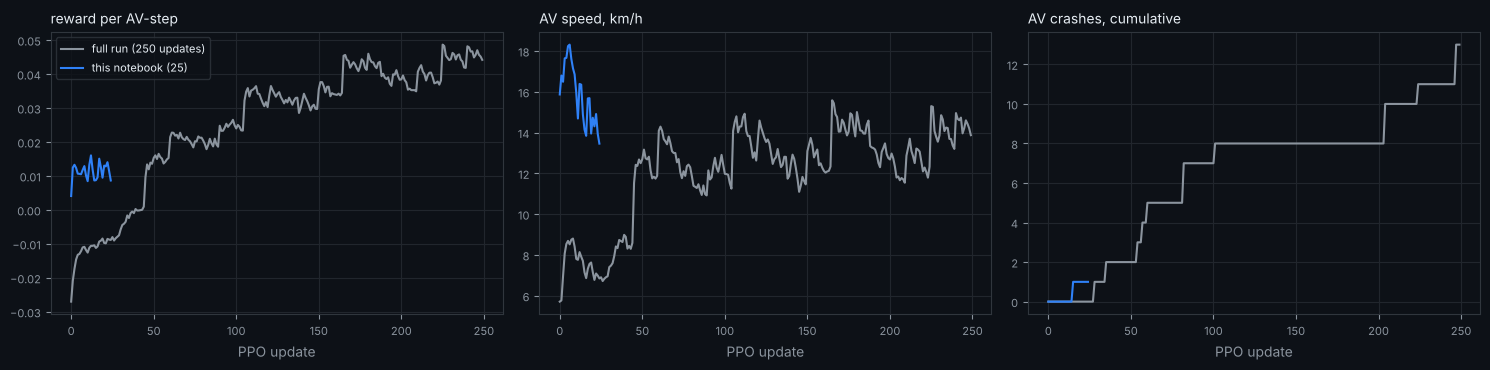

In [3]:
import json
plt.rcParams.update({"axes.titlecolor": "#e6edf3", "axes.labelcolor": "#8b949e"})
def dark(ax):
    ax.set_facecolor("#0d1117"); ax.tick_params(colors="#8b949e", labelsize=8); ax.grid(color="#21262d")
    for s in ax.spines.values(): s.set_color("#30363d")
    ax.title.set_color("#e6edf3"); ax.xaxis.label.set_color("#8b949e"); ax.yaxis.label.set_color("#8b949e")
demo = json.load(open("results/notebooks/ppo_demo/train_log.json"))
full = json.load(open("results/xnet/train_log.json"))
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), facecolor="#0d1117")
for log, name, c in ((full, "full run (250 updates)", "#8b949e"), (demo, "this notebook (25)", "#2f81f7")):
    u = [r["update"] for r in log]
    axs[0].plot(u, [r["reward_per_step"] for r in log], color=c, label=name)
    axs[1].plot(u, [r["av_speed_kmh"] for r in log], color=c)
    axs[2].plot(u, np.cumsum([r["av_crashes"] for r in log]), color=c)
for a, t_ in zip(axs, ("reward per AV-step", "AV speed, km/h", "AV crashes, cumulative")):
    a.set_title(t_, loc="left", fontsize=10); a.set_xlabel("PPO update"); dark(a)
axs[0].legend(facecolor="#0d1117", edgecolor="#30363d", labelcolor="#e6edf3", fontsize=8)
fig.tight_layout(); display(fig); plt.close(fig)

## Fine-tune with your own reward

`init=` continues from a saved policy (and skips behaviour cloning); `reward=` overrides any weight of `xnet.sim.Reward`. Here the
bundled policy is pushed to keep longer headways for 10 updates.

In [4]:
t = time.time()
P.train(out="results/notebooks/ppo_headway", updates=10, n_envs=4, warm=60, init=av_world.data_path("policy.npz"), reward={"headway": 1.0})
print(f"{time.time() - t:.0f} s")

warm-up 6 s


{"update": 0, "time_s": 12.7, "reward_per_step": 0.084, "transitions": 4211, "kl": 0.008, "vl": 0.26, "log_std": [-2.3499999046325684, -1.5570000410079956], "av_hours": 0.24, "av_speed_kmh": 26.338, "av_hard_per_h": 8.407289505004883, "av_jerk_rms": 4.003, "av_crashes": 0, "av_red": 0, "av_near": 0, "av_shield_share": 0.065, "av_trip_min": 0.31, "human_trip_min": 0.141, "trips_finished": 6, "teleports": 0, "crashes": 0}


{"update": 9, "time_s": 21.3, "reward_per_step": 0.075, "transitions": 12943, "kl": 0.004, "vl": 0.133, "log_std": [-2.377000093460083, -1.565000057220459], "av_hours": 0.73, "av_speed_kmh": 21.583, "av_hard_per_h": 4.106464862823486, "av_jerk_rms": 3.671, "av_crashes": 0, "av_red": 0, "av_near": 0, "av_shield_share": 0.041, "av_trip_min": 2.04, "human_trip_min": 1.226, "trips_finished": 8, "teleports": 0, "crashes": 0}


23 s


## Score it on AVBench

`avrl.bench.evaluate` runs a policy on benchmark scenarios with the same warm states and random numbers as every leaderboard entry
(~30 s per scenario here) and returns the scorecard: the av_world score (0-100) and the raw metrics.

In [5]:
from avrl import bench
lb = json.load(open("results/bench/leaderboard.json"))["scores"]
rows = {"rule-based AV (leaderboard)": lb["rule-based AV"]["nominal"], "PPO 130k steps (leaderboard)": lb["PPO, 130k steps (xnet)"]["nominal"]}
for name, path in (("this notebook's PPO", "results/notebooks/ppo_demo/policy.npz"), ("bundled policy", av_world.data_path("policy.npz")), ("bundled + headway fine-tune", "results/notebooks/ppo_headway/policy.npz")):
    t = time.time()
    rows[name] = bench.evaluate(path, ["nominal"])["scenarios"]["nominal"]
    print(f"{name}: {time.time() - t:.0f} s")
print(f"\n{'policy':30s} {'score':>6s} {'crashes/AV-h':>13s} {'unaided':>8s} {'comfort':>8s} {'progress':>8s} {'envelope':>9s}")
for n, s in rows.items():
    m = s["metrics"]
    print(f"{n:30s} {s['av_score']:6.1f} {m['crash_per_h']:13.3f} {m['crash_per_h_unaided']:8.3f} {m['comfort_pass']:8.3f} {m['progress']:8.3f} {m['filter_share']:9.3f}")

this notebook's PPO: 30 s


bundled policy: 29 s


bundled + headway fine-tune: 29 s

policy                          score  crashes/AV-h  unaided  comfort progress  envelope
rule-based AV (leaderboard)      72.2         0.025    0.025    0.904    1.061     0.000
PPO 130k steps (leaderboard)      0.6         0.000    2.385    0.988    1.030     0.026
this notebook's PPO               0.0         0.000  132.869    0.961    1.103     0.479
bundled policy                    7.6         0.000    0.492    0.980    1.108     0.022
bundled + headway fine-tune      18.7         0.000    0.220    0.981    1.105     0.019


`envelope` is the share of AV time the safety envelope had to cut the policy's command; `unaided` is the crash rate with no
envelope at all. Read the table honestly: a 25-update policy leans on the envelope much of the time and crashes often without it,
and the score says so. That is the point of the scorecard: driving smoothly *behind* a safety filter is not the same as driving
safely. Ten fine-tuning updates with a stronger headway penalty did help the bundled policy here (fewer unaided crashes, a higher score),
but on one scenario and one seed: check it on more scenarios before believing it, and note that even the best learned policies on
the leaderboard do not beat the rule-based AV's core score.

## Going further

* The full run: `python -m avrl.xppo --out results/my_run` (~10 min, 4 cores), or on a GPU with many more copies:
  `n_envs=256` (`scripts/gpu_session.sh` runs it end to end; [docs/SPEED.md](../docs/SPEED.md) has the throughput).
* Training without the envelope, with the barrier function as a teacher: `reward={"barrier": ..., "veto": ...}` and
  [docs/RL.md](../docs/RL.md).
* Your own algorithm: notebook [02](02_rl_environment.ipynb) has the environment; `avrl/xppo.py` is ~300 lines to copy from.